## Problema - Gestión de tareas con Heap y Cola de Prioridad

Un centro de cómputo recibe tareas que deben ser procesadas por sus servidores. Cada tarea tiene un código, un nombre y una prioridad, y las tareas con prioridad numérica mayor se procesan primero. Para administrarlas se usa un Max-Heap implementado con un arreglo, sobre el cual se construye una cola de prioridad y se aplica HeapSort.

In [1]:
# @title Ingrese datos
nombre_estudiante = "Juan Pablo Leon, Mateo Barrios, Santiago Lugo y Alejandro Peña" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}

## 1) Descripción del problema **[1 pts]**

El programa registra n tareas con su código, nombre y prioridad, y guarda las prioridades en el mismo orden en que se ingresan. Con esa lista construye un Max-Heap sobre un arreglo, de modo que la prioridad de cada padre sea mayor o igual que la de sus hijos. Para un nodo en la posición i, sus hijos están en 2i + 1 y 2i + 2, y su padre en (i − 1) // 2.

Sobre el heap se implementa una cola de prioridad con tres operaciones: consultar la tarea de mayor prioridad (MAXIMUM), procesarla (EXTRACT-MAX) e insertar una tarea nueva sin romper la propiedad del heap. Por último, las prioridades se ordenan de menor a mayor con HeapSort, sin usar `heapq`, `sort()` ni `sorted()`.

## 2) Requerimientos **[2 pts]**

### Requerimientos funcionales
1. Solicitar la cantidad n de tareas y, para cada una, su código, nombre y prioridad.
2. Mostrar la lista original de prioridades en el orden de ingreso.
3. Implementar MAX-HEAPIFY y BUILD-MAX-HEAP para construir el Max-Heap.
4. Mostrar el Max-Heap como arreglo y como árbol en texto.
5. Implementar MAXIMUM para consultar la raíz sin eliminarla.
6. Implementar EXTRACT-MAX para retirar la tarea de mayor prioridad, mostrarla y reorganizar el heap.
7. Insertar una tarea nueva conservando la propiedad del Max-Heap y mostrar su posición.
8. Implementar HeapSort y mostrar la lista original, el Max-Heap y la lista ordenada.

### Requerimientos no funcionales
1. El heap se representa con un arreglo (lista de Python), sin nodos ni punteros.
2. No se usan `heapq`, `sort()` ni `sorted()`.
3. MAX-HEAPIFY, EXTRACT-MAX e insertar trabajan en O(log n); BUILD-MAX-HEAP en O(n) y HeapSort en O(n log n).
4. Los mensajes en consola son claros y muestran cada paso del proceso.
5. El programa se prueba con al menos 6 tareas.

## 3) Historias de usuario **[2 pts]**

Como operador del centro de cómputo, quiero registrar n tareas con código, nombre y prioridad, para tenerlas en el sistema. Criterios de aceptación: Se pide n y luego exactamente n tareas. Se muestra la lista de prioridades en el orden de ingreso.

Como operador, quiero organizar las tareas en un Max-Heap, para saber siempre cuál va primero. Criterios de aceptación: Todo padre tiene prioridad mayor o igual que sus hijos. Se muestra el arreglo y el árbol.

Como operador, quiero consultar la tarea de mayor prioridad sin sacarla, para saber cuál sigue. Criterios de aceptación: Se muestra la tarea de la raíz y el heap no cambia.

Como servidor, quiero procesar la tarea de mayor prioridad, para atender primero lo más urgente. Criterios de aceptación: Se retira la raíz, se muestra la tarea procesada y el nuevo heap sigue siendo válido.

Como operador, quiero agregar una tarea urgente, para que quede en la posición que le corresponde. Criterios de aceptación: La nueva tarea sube mientras su padre tenga menor prioridad y el heap sigue siendo válido.

Como operador, quiero ver las prioridades ordenadas, para analizar la carga de trabajo. Criterios de aceptación: HeapSort devuelve las prioridades de menor a mayor sin usar sort() ni sorted().

## 4) Diagramas de flujo **[5 pts]**

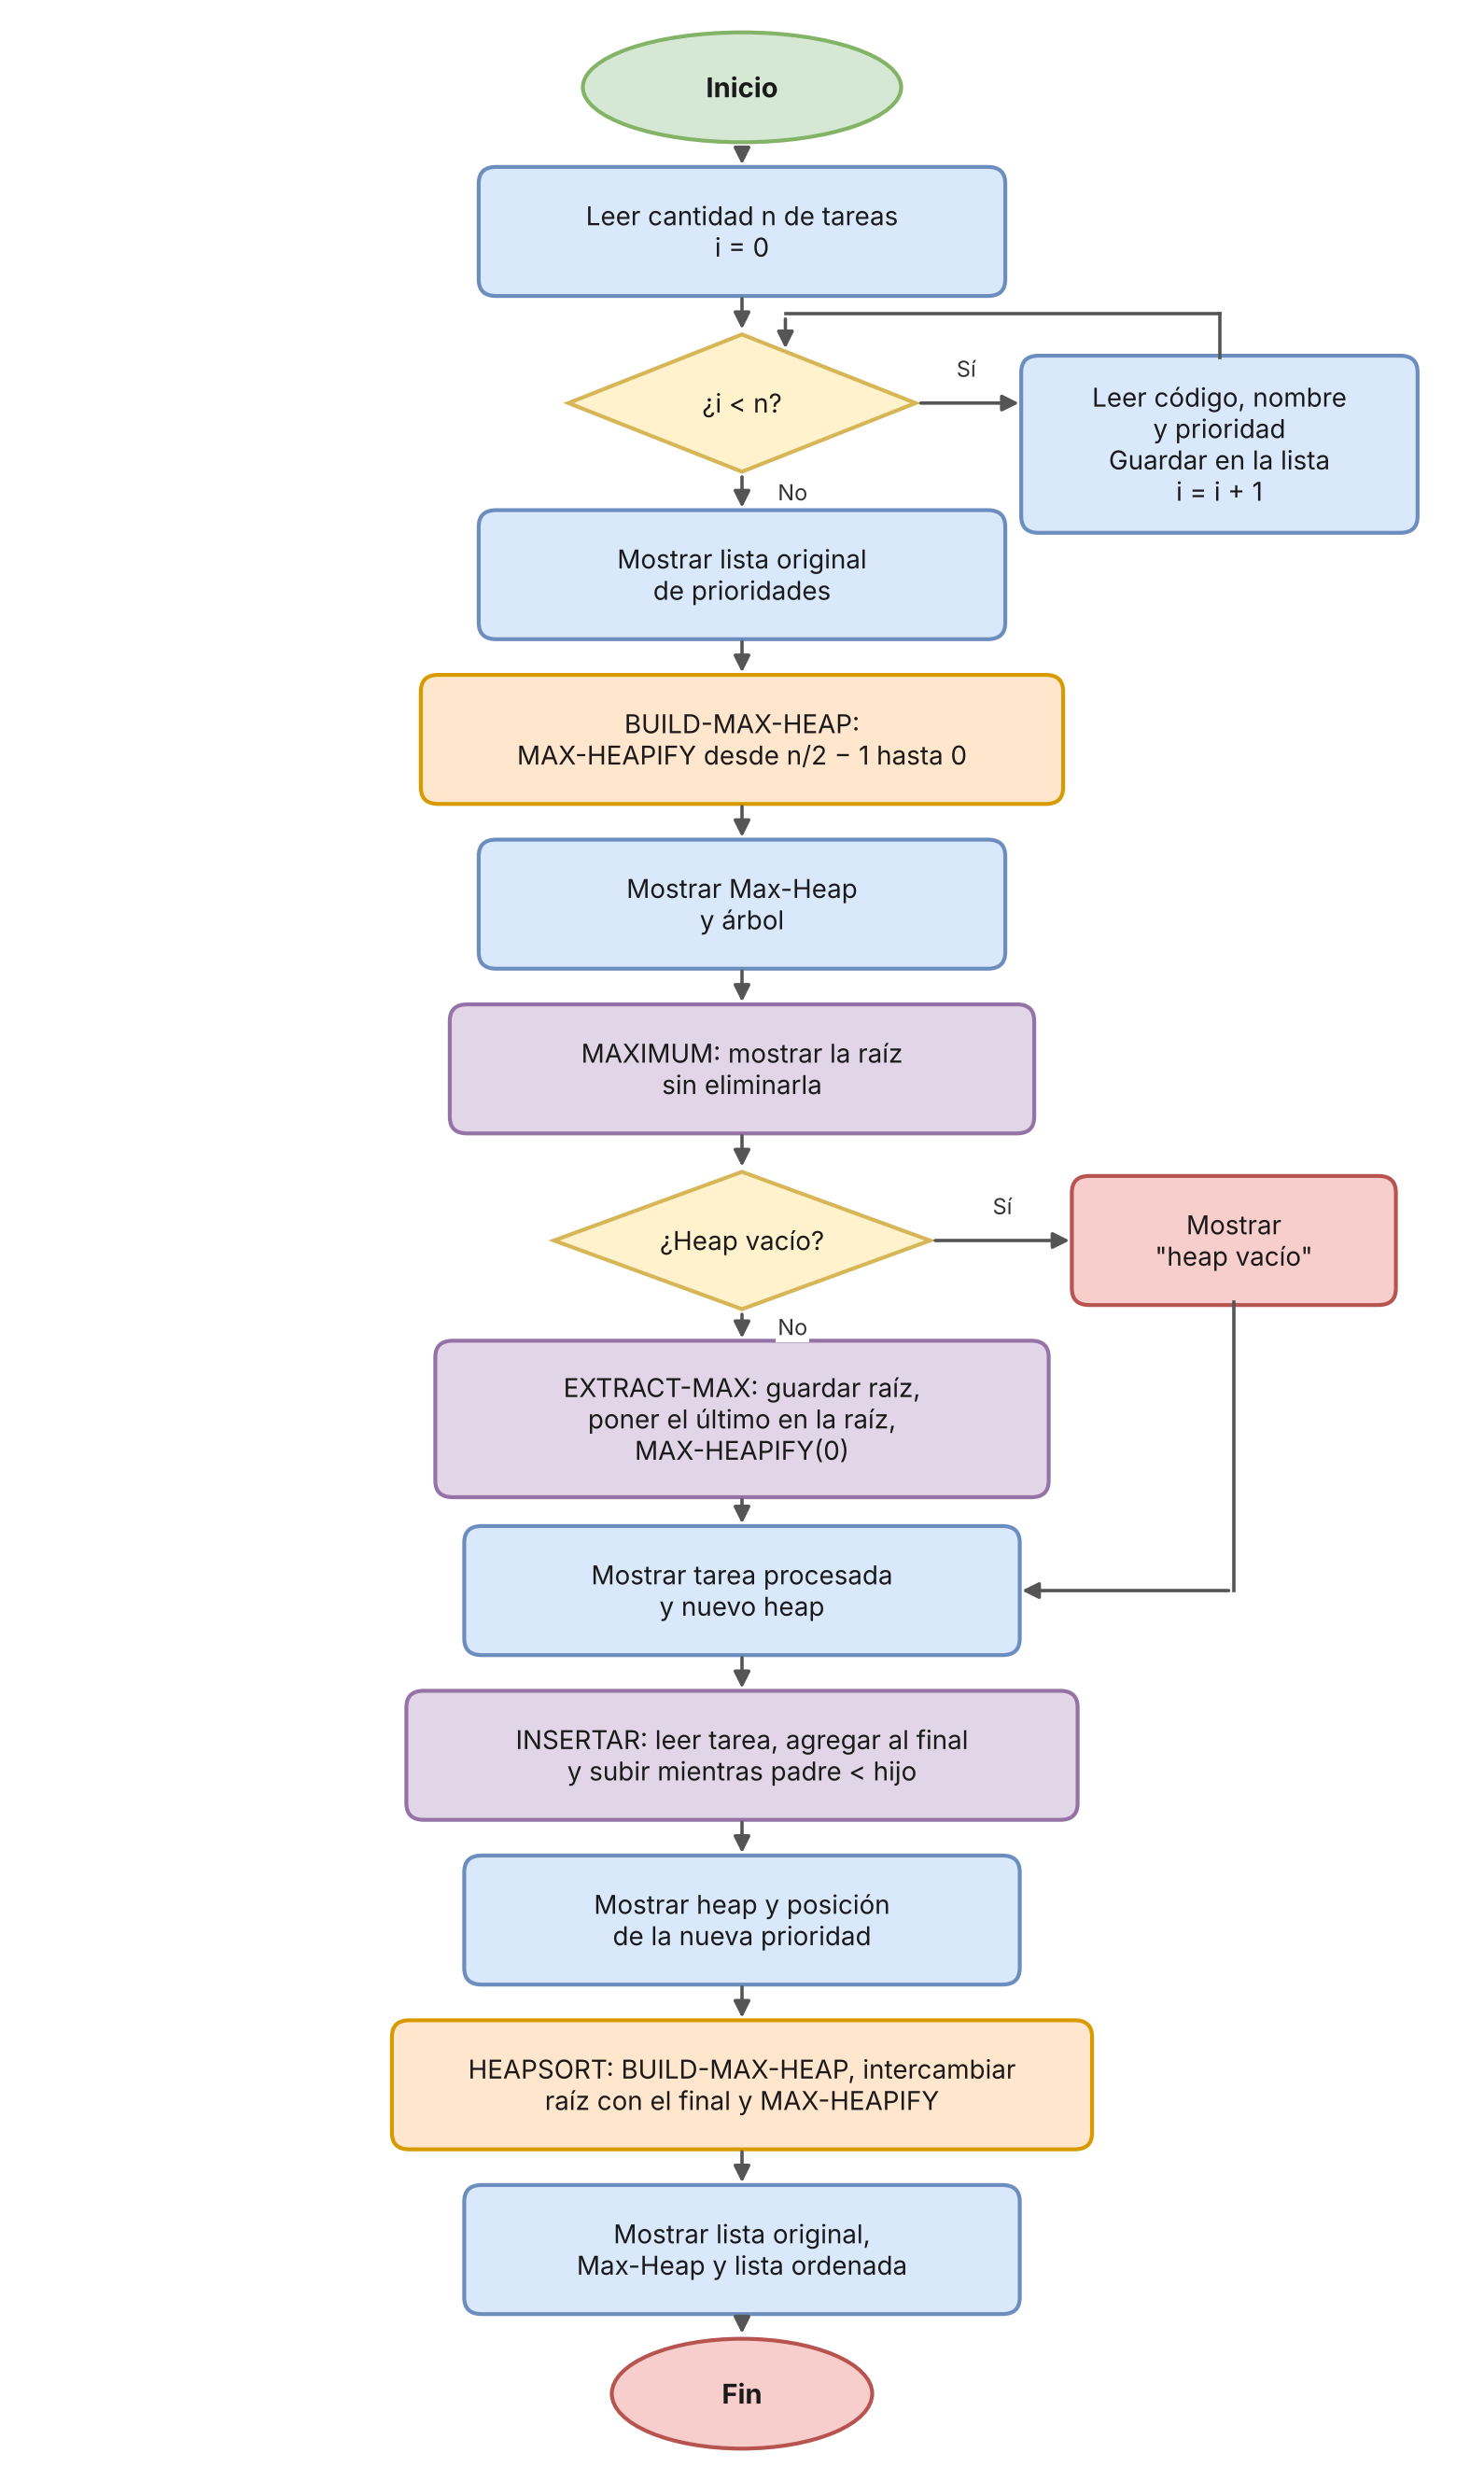

El diagrama muestra el proceso completo. Primero se leen las n tareas con un ciclo y se muestra la lista original. Luego BUILD-MAX-HEAP llama a MAX-HEAPIFY desde el último nodo con hijos (n/2 − 1) hasta la raíz. Con el heap listo, MAXIMUM consulta la raíz y EXTRACT-MAX la retira, pasa el último elemento a la raíz y vuelve a aplicar MAX-HEAPIFY; si el heap está vacío, solo se informa. Después se inserta una tarea nueva al final del arreglo y se sube mientras su padre tenga menor prioridad. Al final, HeapSort construye el heap, intercambia la raíz con la última posición no ordenada y aplica MAX-HEAPIFY sobre la parte restante.

### 5) Análisis de complejidad **[15 pts]**

### Justificación

El heap es un árbol binario completo guardado en un arreglo, así que su altura es ⌊log₂ n⌋.

- **MAX-HEAPIFY:** en cada llamada compara un nodo con sus dos hijos y, si hace falta, baja un nivel. Como máximo baja la altura del árbol: T(n) = T(n/2) + c, es decir, **O(log n)**. En el mejor caso el nodo ya cumple la propiedad y cuesta **O(1)**.
- **BUILD-MAX-HEAP:** llama a MAX-HEAPIFY sobre los n/2 nodos que tienen hijos. A primera vista serían O(n log n), pero la mayoría de nodos están cerca de las hojas y bajan pocos niveles. Sumando por alturas, T(n) = Σ ⌈n / 2^(h+1)⌉ · O(h) = **O(n)**.
- **MAXIMUM:** solo lee la posición 0: **O(1)**.
- **EXTRACT-MAX:** mueve el último elemento a la raíz y aplica MAX-HEAPIFY: **O(log n)**.
- **Insertar:** agrega al final y sube por los padres; como máximo recorre la altura: **O(log n)**. En el mejor caso la nueva prioridad es menor o igual que la de su padre y cuesta **O(1)**.
- **HEAPSORT:** construye el heap en O(n) y hace n − 1 extracciones, cada una con MAX-HEAPIFY en O(log n):

T(n) = O(n) + (n − 1) · O(log n) = **O(n log n)**

- **Mejor caso de HeapSort:** todas las prioridades son iguales. Ninguna llamada a MAX-HEAPIFY intercambia, y cada una cuesta O(1): **T(n) = O(n)**.
- **Peor caso de HeapSort:** prioridades distintas; en cada extracción el elemento que llega a la raíz baja hasta una hoja: **T(n) = O(n log n)**.

| Operación | Mejor caso | Peor caso |
|---|---|---|
| MAX-HEAPIFY | O(1) | O(log n) |
| BUILD-MAX-HEAP | O(n) | O(n) |
| MAXIMUM | O(1) | O(1) |
| EXTRACT-MAX | O(1) | O(log n) |
| Insertar | O(1) | O(log n) |
| HEAPSORT | O(n) | O(n log n) |

La memoria adicional es O(1) para las operaciones del heap, porque todo se hace sobre el mismo arreglo. En el código, `build_max_heap` y `heapsort` trabajan sobre una copia para no perder la lista original que pide mostrar el enunciado.

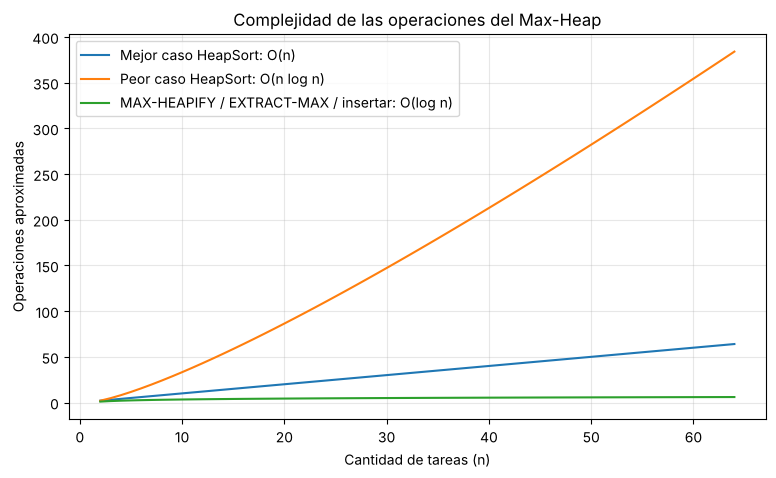

In [2]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(2, 65)

plt.figure(figsize=(9, 5))
plt.plot(n, n, label="Mejor caso HeapSort: O(n)")
plt.plot(n, n * np.log2(n), label="Peor caso HeapSort: O(n log n)")
plt.plot(n, np.log2(n), label="MAX-HEAPIFY / EXTRACT-MAX / insertar: O(log n)")
plt.xlabel("Cantidad de tareas (n)")
plt.ylabel("Operaciones aproximadas")
plt.title("Complejidad de las operaciones del Max-Heap")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6) Código funcional **[15 pts]**

Cada tarea se guarda como un diccionario con `codigo`, `nombre` y `prioridad`, y el heap es una lista de esas tareas. Las comparaciones se hacen por prioridad, así la cola de prioridad conserva toda la información de la tarea y no solo el número.

In [3]:
def padre(i):
    return (i - 1) // 2


def izquierdo(i):
    return 2 * i + 1


def derecho(i):
    return 2 * i + 2


def prioridades(heap):
    return [tarea["prioridad"] for tarea in heap]


def mostrar_tarea(tarea):
    return f"{tarea['codigo']} - {tarea['nombre']} - Prioridad: {tarea['prioridad']}"


def max_heapify(heap, i, tam):
    izq = izquierdo(i)
    der = derecho(i)
    mayor = i
    if izq < tam and heap[izq]["prioridad"] > heap[mayor]["prioridad"]:
        mayor = izq
    if der < tam and heap[der]["prioridad"] > heap[mayor]["prioridad"]:
        mayor = der
    if mayor != i:
        heap[i], heap[mayor] = heap[mayor], heap[i]
        max_heapify(heap, mayor, tam)


def build_max_heap(tareas):
    heap = tareas[:]
    for i in range(len(heap) // 2 - 1, -1, -1):
        max_heapify(heap, i, len(heap))
    return heap


def maximum(heap):
    if len(heap) == 0:
        return None
    return heap[0]


def extract_max(heap):
    if len(heap) == 0:
        return None
    maximo = heap[0]
    heap[0] = heap[-1]
    heap.pop()
    max_heapify(heap, 0, len(heap))
    return maximo


def insertar(heap, tarea):
    heap.append(tarea)
    i = len(heap) - 1
    while i > 0 and heap[padre(i)]["prioridad"] < heap[i]["prioridad"]:
        heap[i], heap[padre(i)] = heap[padre(i)], heap[i]
        i = padre(i)


def heapsort(tareas):
    heap = build_max_heap(tareas)
    for fin in range(len(heap) - 1, 0, -1):
        heap[0], heap[fin] = heap[fin], heap[0]
        max_heapify(heap, 0, fin)
    return heap


def mostrar_arbol(heap):
    n = len(heap)
    if n == 0:
        print("    (heap vacío)")
        return
    niveles = 0
    while 2 ** niveles - 1 < n:
        niveles += 1
    ancho = 4 * 2 ** (niveles - 1)
    for d in range(niveles):
        tramo = ancho / 2 ** d
        fila = [" "] * (ancho + 4)
        ramas = [" "] * (ancho + 4)
        for j in range(2 ** d):
            i = 2 ** d - 1 + j
            if i >= n:
                break
            x = int((j + 0.5) * tramo)
            texto = str(heap[i]["prioridad"])
            inicio = x - len(texto) // 2
            for k, c in enumerate(texto):
                fila[inicio + k] = c
            if izquierdo(i) < n:
                ramas[x - int(tramo / 4) + int(tramo / 8)] = "/"
            if derecho(i) < n:
                ramas[x + int(tramo / 4) - int(tramo / 8)] = "\\"
        print("    " + "".join(fila).rstrip())
        if d < niveles - 1 and "".join(ramas).strip():
            print("    " + "".join(ramas).rstrip())


def registrar_tareas():
    n = int(input("Cantidad de tareas: "))
    tareas = []
    for k in range(n):
        print(f"\nTarea {k + 1}")
        codigo = input("Código: ")
        nombre = input("Nombre: ")
        prioridad = int(input("Prioridad: "))
        tareas.append({"codigo": codigo, "nombre": nombre, "prioridad": prioridad})
    return tareas


def pedir_tarea():
    codigo = input("Código: ")
    nombre = input("Nombre: ")
    prioridad = int(input("Prioridad: "))
    return {"codigo": codigo, "nombre": nombre, "prioridad": prioridad}


def programa():
    print("PUNTO 1. REGISTRO DE TAREAS")
    tareas = registrar_tareas()
    print("\nTareas registradas:")
    for tarea in tareas:
        print("  " + mostrar_tarea(tarea))
    print("\nLista original de prioridades:", prioridades(tareas))

    print("\nPUNTO 2. CONSTRUCCIÓN DEL MAX-HEAP")
    heap = build_max_heap(tareas)
    print("Lista original:", prioridades(tareas))
    print("Max-Heap:", prioridades(heap))
    print("\nÁrbol:")
    mostrar_arbol(heap)

    print("\nPUNTO 3. COLA DE PRIORIDAD")
    print("\nA. MAXIMUM")
    tarea = maximum(heap)
    if tarea is None:
        print("El heap está vacío")
    else:
        print(f"Tarea de mayor prioridad: {tarea['codigo']} - {tarea['nombre']} Prioridad: {tarea['prioridad']}")

    print("\nB. EXTRACT-MAX")
    tarea = extract_max(heap)
    if tarea is None:
        print("El heap está vacío, no hay tareas para procesar")
    else:
        print(f"Tarea procesada: {tarea['codigo']} - {tarea['nombre']}")
    print("Nuevo Heap:", prioridades(heap))
    mostrar_arbol(heap)

    print("\nC. INSERTAR NUEVA TAREA")
    nueva = pedir_tarea()
    insertar(heap, nueva)
    posicion = heap.index(nueva)
    print(f"\nTarea insertada: {mostrar_tarea(nueva)}")
    print("Heap después de insertar:", prioridades(heap))
    print(f"La prioridad {nueva['prioridad']} quedó en la posición {posicion} del arreglo")
    mostrar_arbol(heap)

    print("\nPUNTO 4. HEAPSORT")
    print("Lista original:", prioridades(tareas))
    print("Max-Heap:", prioridades(build_max_heap(tareas)))
    print("Lista ordenada:", prioridades(heapsort(tareas)))

### Punto 5. Prueba final

Ejecución con 6 tareas. Se registran T01 a T06 y, en la inserción, se agrega T07 - Actualizar servidor con prioridad 12.

In [4]:
programa()

PUNTO 1. REGISTRO DE TAREAS
Cantidad de tareas: 6

Tarea 1
Código: T01
Nombre: Compilar proyecto
Prioridad: 8

Tarea 2
Código: T02
Nombre: Generar backup
Prioridad: 4

Tarea 3
Código: T03
Nombre: Renderizar video
Prioridad: 10

Tarea 4
Código: T04
Nombre: Procesar correos
Prioridad: 3

Tarea 5
Código: T05
Nombre: Ejecutar pruebas
Prioridad: 7

Tarea 6
Código: T06
Nombre: Escanear vulnerabilidades
Prioridad: 9

Tareas registradas:
  T01 - Compilar proyecto - Prioridad: 8
  T02 - Generar backup - Prioridad: 4
  T03 - Renderizar video - Prioridad: 10
  T04 - Procesar correos - Prioridad: 3
  T05 - Ejecutar pruebas - Prioridad: 7
  T06 - Escanear vulnerabilidades - Prioridad: 9

Lista original de prioridades: [8, 4, 10, 3, 7, 9]

PUNTO 2. CONSTRUCCIÓN DEL MAX-HEAP
Lista original: [8, 4, 10, 3, 7, 9]
Max-Heap: [10, 7, 9, 3, 4, 8]

Árbol:
           10
          /   \
        7       9
       / \     /
      3   4   8

PUNTO 3. COLA DE PRIORIDAD

A. MAXIMUM
Tarea de mayor prioridad: T03 - Re

## 7) Tests aplicados **[15 pts]**

Se comprueba cada operación con los datos del enunciado y con casos borde: heap vacío, un solo elemento, prioridades repetidas y listas ya ordenadas o invertidas.

In [5]:
def tareas_de(lista):
    return [{"codigo": f"T{k + 1:02d}", "nombre": f"Tarea {k + 1}", "prioridad": p} for k, p in enumerate(lista)]


def es_max_heap(heap):
    for i in range(len(heap)):
        if izquierdo(i) < len(heap) and heap[i]["prioridad"] < heap[izquierdo(i)]["prioridad"]:
            return False
        if derecho(i) < len(heap) and heap[i]["prioridad"] < heap[derecho(i)]["prioridad"]:
            return False
    return True


def esta_ordenada(lista):
    for i in range(len(lista) - 1):
        if lista[i] > lista[i + 1]:
            return False
    return True


def test(nombre, obtenido, esperado):
    assert obtenido == esperado, f"{nombre}: se obtuvo {obtenido}, pero se esperaba {esperado}"
    print(f"Paso caso de prueba {nombre}: {obtenido}")


ejemplo = tareas_de([8, 4, 10, 3, 7])
heap = build_max_heap(ejemplo)
test("BUILD-MAX-HEAP del enunciado", prioridades(heap), [10, 7, 8, 3, 4])
test("La lista original no cambia", prioridades(ejemplo), [8, 4, 10, 3, 7])
test("MAXIMUM", maximum(heap)["prioridad"], 10)
test("MAXIMUM no elimina", len(heap), 5)
test("EXTRACT-MAX devuelve la raíz", extract_max(heap)["prioridad"], 10)
test("Heap después de EXTRACT-MAX", prioridades(heap), [8, 7, 4, 3])
insertar(heap, {"codigo": "T06", "nombre": "Actualizar servidor", "prioridad": 12})
test("Insertar prioridad 12", prioridades(heap), [12, 8, 4, 3, 7])
test("12 queda en la raíz", heap[0]["codigo"], "T06")
test("HEAPSORT del enunciado", prioridades(heapsort(ejemplo)), [3, 4, 7, 8, 10])

seis = tareas_de([8, 4, 10, 3, 7, 9])
h6 = build_max_heap(seis)
test("BUILD-MAX-HEAP con 6 tareas", prioridades(h6), [10, 7, 9, 3, 4, 8])
extract_max(h6)
test("EXTRACT-MAX con 6 tareas", prioridades(h6), [9, 7, 8, 3, 4])
insertar(h6, {"codigo": "T07", "nombre": "Actualizar servidor", "prioridad": 12})
test("Insertar con 6 tareas", prioridades(h6), [12, 7, 9, 3, 4, 8])
test("HEAPSORT con 6 tareas", prioridades(heapsort(seis)), [3, 4, 7, 8, 9, 10])

test("Heap vacío: MAXIMUM", maximum([]), None)
test("Heap vacío: EXTRACT-MAX", extract_max([]), None)
test("Un solo elemento", prioridades(heapsort(tareas_de([5]))), [5])
test("Prioridades repetidas", prioridades(heapsort(tareas_de([5, 5, 5, 5]))), [5, 5, 5, 5])
test("Lista ya ordenada", prioridades(heapsort(tareas_de([1, 2, 3, 4, 5, 6]))), [1, 2, 3, 4, 5, 6])
test("Lista invertida", prioridades(heapsort(tareas_de([6, 5, 4, 3, 2, 1]))), [1, 2, 3, 4, 5, 6])

import random
random.seed(7)
for prueba in range(200):
    datos = [random.randint(1, 50) for _ in range(random.randint(1, 30))]
    h = build_max_heap(tareas_de(datos))
    assert es_max_heap(h)
    salidas = [extract_max(h)["prioridad"] for _ in range(len(datos))]
    assert esta_ordenada(salidas[::-1])
    assert esta_ordenada(prioridades(heapsort(tareas_de(datos))))
print("Paso caso de prueba 200 listas aleatorias: el heap siempre es válido y HeapSort siempre ordena")

Paso caso de prueba BUILD-MAX-HEAP del enunciado: [10, 7, 8, 3, 4]
Paso caso de prueba La lista original no cambia: [8, 4, 10, 3, 7]
Paso caso de prueba MAXIMUM: 10
Paso caso de prueba MAXIMUM no elimina: 5
Paso caso de prueba EXTRACT-MAX devuelve la raíz: 10
Paso caso de prueba Heap después de EXTRACT-MAX: [8, 7, 4, 3]
Paso caso de prueba Insertar prioridad 12: [12, 8, 4, 3, 7]
Paso caso de prueba 12 queda en la raíz: T06
Paso caso de prueba HEAPSORT del enunciado: [3, 4, 7, 8, 10]
Paso caso de prueba BUILD-MAX-HEAP con 6 tareas: [10, 7, 9, 3, 4, 8]
Paso caso de prueba EXTRACT-MAX con 6 tareas: [9, 7, 8, 3, 4]
Paso caso de prueba Insertar con 6 tareas: [12, 7, 9, 3, 4, 8]
Paso caso de prueba HEAPSORT con 6 tareas: [3, 4, 7, 8, 9, 10]
Paso caso de prueba Heap vacío: MAXIMUM: None
Paso caso de prueba Heap vacío: EXTRACT-MAX: None
Paso caso de prueba Un solo elemento: [5]
Paso caso de prueba Prioridades repetidas: [5, 5, 5, 5]
Paso caso de prueba Lista ya ordenada: [1, 2, 3, 4, 5, 6]
Pas